In [117]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [118]:
df=pd.read_csv("ecommerce_dirty_dataset.csv")

# Basic Investigation

In [119]:
df.head()

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
0,1,2022-04-13,2022-04-14,1992,Consumer,East,Odisha,Clothing,Kids,Kids Product 3,14492.0,5,0.20,1621.85,328.0,Cash on Delivery
1,2,2023-03-12,2023-03-13,4347,Corporate,East,Bihar,Electronics,Laptop,Laptop Product 100,47633.0,1,0.05,5774.48,340.0,Cash on Delivery
2,3,2022-09-28,2022-10-04,2195,Corporate,West,Maharashtra,Clothing,Women,Women Product 1,4058.1,1,0.10,521.04,348.0,Credit Card
3,4,2022-04-17,2022-04-21,3425,Consumer,South,Tamil Nadu,Electronics,Laptop,Laptop Product 139,61980.0,4,0.00,6695.36,62.0,Cash on Delivery
4,5,2022-03-13,2022-03-20,2967,NaN,North,Haryana,Clothing,Women,Women Product 50,6807.0,3,0.00,2653.83,94.0,Debit Card


In [120]:
df.columns

Index(['Order_ID', 'Order_Date', 'Ship_Date', 'Customer_ID',
       'Customer_Segment', 'Region', 'State', 'Product_Category',
       'Sub_Category', 'Product_Name', 'Sales', 'Quantity', 'Discount',
       'Profit', 'Shipping_Cost', 'Payment_Mode'],
      dtype='object')

In [121]:
df.shape

(100500, 16)

In [122]:
df.isna().sum()

Order_ID               0
Order_Date             0
Ship_Date              0
Customer_ID            0
Customer_Segment    3019
Region                 0
State                  0
Product_Category       0
Sub_Category           0
Product_Name           0
Sales                  0
Quantity               0
Discount               0
Profit              3019
Shipping_Cost       3006
Payment_Mode           0
dtype: int64

In [123]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100500 entries, 0 to 100499
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Order_ID          100500 non-null  int64  
 1   Order_Date        100500 non-null  object 
 2   Ship_Date         100500 non-null  object 
 3   Customer_ID       100500 non-null  int64  
 4   Customer_Segment  97481 non-null   object 
 5   Region            100500 non-null  object 
 6   State             100500 non-null  object 
 7   Product_Category  100500 non-null  object 
 8   Sub_Category      100500 non-null  object 
 9   Product_Name      100500 non-null  object 
 10  Sales             100500 non-null  float64
 11  Quantity          100500 non-null  int64  
 12  Discount          100500 non-null  float64
 13  Profit            97481 non-null   float64
 14  Shipping_Cost     97494 non-null   float64
 15  Payment_Mode      100500 non-null  object 
dtypes: float64(4), int64

# Skewness , Outliers

In [124]:
from scipy.stats import skew, kurtosis # importing skew and kurtosis for finding the distribution

In [125]:
skew(df["Sales"]) ## right skewness (+ve)

np.float64(2.124260612325759)

In [126]:
q1 = df["Sales"].quantile(0.25)
q3 = df["Sales"].quantile(0.75)
iqr = q3-q1 
lower_bound = q1-1.5* iqr
upper_bound = q3+1.5* iqr
df[(df["Sales"]<lower_bound) | (df["Sales"]>upper_bound)]# outliers detection with IQR method 

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
15,16,2022-04-10,2022-04-17,2379,Home Office,East,Odisha,Electronics,Laptop,Laptop Product 110,258922.75,5,0.15,59186.74,231.0,Cash on Delivery
16,17,2023-10-26,2023-10-29,4077,Consumer,East,Odisha,Electronics,Laptop,Laptop Product 69,357322.50,5,0.10,97920.08,377.0,Cash on Delivery
24,25,2022-07-11,2022-07-12,1149,Corporate,West,Gujarat,Electronics,Accessories,Accessories Product 36,278719.20,4,0.10,73920.24,317.0,Debit Card
25,26,2022-10-04,2022-10-05,1412,Consumer,North,Haryana,Electronics,Laptop,Laptop Product 16,239243.25,5,0.05,93913.43,285.0,Cash on Delivery
37,38,2023-12-01,2023-12-02,4726,Home Office,East,Odisha,Electronics,Mobile,Mobile Product 64,170107.95,3,0.05,35690.17,287.0,Credit Card
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100455,98393,2022-05-30,2022-06-05,2251,Corporate,North,Haryana,Electronics,Mobile,Mobile Product 3,272293.25,5,0.15,50069.21,248.0,Credit Card
100463,45185,2023-08-20,2023-08-25,3236,Consumer,North,Delhi,Electronics,Mobile,Mobile Product 107,201031.20,3,0.10,48367.86,64.0,Cash on Delivery
100468,50104,2023-08-31,2023-09-02,1375,NaN,West,Rajasthan,Electronics,Mobile,Mobile Product 111,150066.00,3,0.10,35393.03,265.0,Debit Card
100494,68674,2023-05-17,2023-05-18,2872,Home Office,South,Tamil Nadu,Electronics,Mobile,Mobile Product 50,193409.00,5,0.15,67526.41,351.0,Debit Card


In [127]:
skew(df["Profit"]) ## right skewness (+ve)

np.float64(nan)

In [128]:
q1 = df["Profit"].quantile(0.25)
q3 = df["Profit"].quantile(0.75)
iqr = q3-q1
lower_bound = q1-1.5*iqr
upper_bound = q3 + 1.5*iqr
df[(df["Profit"]< lower_bound) | (df["Profit"] > upper_bound)]# outliers detection with IQR method 

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
15,16,2022-04-10,2022-04-17,2379,Home Office,East,Odisha,Electronics,Laptop,Laptop Product 110,258922.75,5,0.15,59186.74,231.0,Cash on Delivery
16,17,2023-10-26,2023-10-29,4077,Consumer,East,Odisha,Electronics,Laptop,Laptop Product 69,357322.50,5,0.10,97920.08,377.0,Cash on Delivery
24,25,2022-07-11,2022-07-12,1149,Corporate,West,Gujarat,Electronics,Accessories,Accessories Product 36,278719.20,4,0.10,73920.24,317.0,Debit Card
25,26,2022-10-04,2022-10-05,1412,Consumer,North,Haryana,Electronics,Laptop,Laptop Product 16,239243.25,5,0.05,93913.43,285.0,Cash on Delivery
29,30,2022-01-22,2022-01-24,4959,Corporate,East,Odisha,Electronics,Laptop,Laptop Product 37,65041.20,4,0.10,500000.00,442.0,Cash on Delivery
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100463,45185,2023-08-20,2023-08-25,3236,Consumer,North,Delhi,Electronics,Mobile,Mobile Product 107,201031.20,3,0.10,48367.86,64.0,Cash on Delivery
100487,62085,2023-05-04,2023-05-06,4111,Corporate,North,Delhi,Electronics,Mobile,Mobile Product 129,99502.00,2,0.00,37942.83,191.0,Debit Card
100491,52088,2022-04-30,2022-05-07,2698,Consumer,East,West Bengal,Electronics,Mobile,Mobile Product 25,99716.80,2,0.20,38432.23,417.0,Debit Card
100494,68674,2023-05-17,2023-05-18,2872,Home Office,South,Tamil Nadu,Electronics,Mobile,Mobile Product 50,193409.00,5,0.15,67526.41,351.0,Debit Card


In [129]:
skew(df["Shipping_Cost"])  ## right skewness (+ve)

np.float64(nan)

In [130]:
q1 = df["Shipping_Cost"].quantile(0.25)
q3 = df["Shipping_Cost"].quantile(0.75)
iqr = q3-q1
lower_bound = q1-1.5*iqr
upper_bound = q3 + 1.5*iqr
df[(df["Shipping_Cost"]< lower_bound) | (df["Shipping_Cost"] > upper_bound)]# outliers detection with IQR method 

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
1426,1427,2023-01-26,2023-01-29,1623,Home Office,North,Punjab,Furniture,Sofa,Sofa Product 101,2813.00,1,0.00,912.15,10000.0,Debit Card
1499,1500,2023-10-27,2023-10-29,3506,Consumer,South,Telangana,Electronics,Laptop,Laptop Product 171,38187.80,1,0.30,9477.21,10000.0,Debit Card
1764,1765,2022-03-05,2022-03-10,3306,Corporate,South,Karnataka,Furniture,Table,Table Product 28,15566.40,4,0.10,4423.36,10000.0,UPI
2510,2511,2022-01-08,2022-01-11,1972,Consumer,West,Maharashtra,Electronics,Laptop,Laptop Product 154,139930.25,5,0.05,22472.26,10000.0,Cash on Delivery
2672,2673,2022-08-22,2022-08-25,4830,Consumer,East,Bihar,Clothing,Kids,Kids Product 134,8124.30,2,0.15,1113.57,10000.0,Cash on Delivery
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95299,95300,2023-06-14,2023-06-21,2866,Home Office,South,Karnataka,Electronics,Laptop,Laptop Product 40,98504.00,4,0.50,26546.85,10000.0,UPI
96342,96343,2022-02-19,2022-02-22,1708,Home Office,North,Delhi,Furniture,Chair,Chair Product 155,17619.00,3,0.00,3190.39,10000.0,UPI
97200,97201,2023-09-03,2023-09-06,1222,Corporate,South,Karnataka,Furniture,Sofa,Sofa Product 84,20281.00,2,0.15,4412.34,10000.0,Cash on Delivery
98696,98697,2022-10-10,2022-10-14,1283,Corporate,West,Maharashtra,Clothing,Women,Women Product 4,571.90,1,0.05,87.70,10000.0,Debit Card


In [131]:
q1 = df["Discount"].quantile(0.25)
q3 = df["Discount"].quantile(0.75)
iqr = q3-q1
lower_bound = q1-1.5*iqr
upper_bound = q3 + 1.5*iqr
df[(df["Discount"]< lower_bound) | (df["Discount"] > upper_bound)]# outlier detection with IQR method

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
11,12,2022-11-27,2022-12-02,3980,Home Office,South,Karnataka,Furniture,Sofa,Sofa Product 169,12032.0,2,0.5,1333.79,68.0,UPI
85,86,2023-12-03,2023-12-10,2898,Corporate,South,Telangana,Furniture,Chair,Chair Product 167,16691.0,2,0.5,1972.75,87.0,Cash on Delivery
165,166,2023-07-10,2023-07-11,3800,Corporate,East,West Bengal,Electronics,Laptop,Laptop Product 102,87045.0,5,0.5,32652.51,278.0,Credit Card
243,244,2022-11-22,2022-11-27,4026,Home Office,North,Punjab,Furniture,Chair,Chair Product 175,5266.5,1,0.5,1570.61,481.0,Credit Card
317,318,2023-04-15,2023-04-19,4663,NaN,South,Telangana,Furniture,Sofa,Sofa Product 126,8757.0,2,0.5,2752.14,365.0,Debit Card
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100384,72515,2023-10-27,2023-10-29,1290,Corporate,North,Delhi,Furniture,Chair,Chair Product 162,14560.0,2,0.5,3045.01,373.0,UPI
100386,33463,2023-06-22,2023-06-23,3273,Home Office,North,Punjab,Furniture,Table,Table Product 124,32854.0,4,0.5,8936.47,322.0,Credit Card
100408,418,2022-02-22,2022-02-24,1606,Consumer,East,Odisha,Clothing,Men,Men Product 177,2047.0,2,0.5,335.46,296.0,Debit Card
100448,83948,2023-12-15,2023-12-22,4641,Corporate,South,Tamil Nadu,Electronics,Mobile,Mobile Product 84,90568.5,3,0.5,23674.37,198.0,UPI


In [132]:
skew(df["Discount"])  ## right skewness (+ve) of disocunt

np.float64(1.8330692002112594)

In [133]:
skew(df["Quantity"])  ## right skewness (+ve) of quanity

np.float64(-0.0009219845059145281)

# Data Cleaning

## Handeling Duplicates in Order ID

In [134]:
df.duplicated(subset="Order_ID").sum() #Duplicates Sum

np.int64(500)

In [135]:
df.drop_duplicates(subset="Order_ID",inplace=True) #Duplicates removal

In [136]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Order_ID          100000 non-null  int64  
 1   Order_Date        100000 non-null  object 
 2   Ship_Date         100000 non-null  object 
 3   Customer_ID       100000 non-null  int64  
 4   Customer_Segment  97000 non-null   object 
 5   Region            100000 non-null  object 
 6   State             100000 non-null  object 
 7   Product_Category  100000 non-null  object 
 8   Sub_Category      100000 non-null  object 
 9   Product_Name      100000 non-null  object 
 10  Sales             100000 non-null  float64
 11  Quantity          100000 non-null  int64  
 12  Discount          100000 non-null  float64
 13  Profit            97000 non-null   float64
 14  Shipping_Cost     97003 non-null   float64
 15  Payment_Mode      100000 non-null  object 
dtypes: float64(4), int64(3), o

## Fixing Dates [Order date , Ship Date]

In [137]:
df["Order_Date"]=pd.to_datetime(df["Order_Date"]) ## changing date format from object to date time

In [138]:
df["Ship_Date"]=pd.to_datetime(df["Ship_Date"]) ## changing date format from object to date time

In [139]:
mask = df["Ship_Date"] < df["Order_Date"]

df.loc[mask, "Ship_Date"] = df.loc[mask, "Order_Date"] 

## Masking the ship date equalt to the order date where ship date < order date

In [140]:
df["Month"] = df["Order_Date"].dt.strftime("%b")
df["Year"] = df["Order_Date"].dt.year
df["Month_num"] = df["Order_Date"].dt.month # extracting month, year, month name from the date column

In [141]:
df["Shipping_days"] = df["Ship_Date"]-df["Order_Date"] # extracting number of days  for shipping from order day

In [142]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype          
---  ------            --------------   -----          
 0   Order_ID          100000 non-null  int64          
 1   Order_Date        100000 non-null  datetime64[ns] 
 2   Ship_Date         100000 non-null  datetime64[ns] 
 3   Customer_ID       100000 non-null  int64          
 4   Customer_Segment  97000 non-null   object         
 5   Region            100000 non-null  object         
 6   State             100000 non-null  object         
 7   Product_Category  100000 non-null  object         
 8   Sub_Category      100000 non-null  object         
 9   Product_Name      100000 non-null  object         
 10  Sales             100000 non-null  float64        
 11  Quantity          100000 non-null  int64          
 12  Discount          100000 non-null  float64        
 13  Profit            97000 non-null   float64        

## Customer ID

In [143]:
df["Customer_ID"].isna().sum()

np.int64(0)

In [144]:
df["Customer_ID"].info()

<class 'pandas.core.series.Series'>
Index: 100000 entries, 0 to 99999
Series name: Customer_ID
Non-Null Count   Dtype
--------------   -----
100000 non-null  int64
dtypes: int64(1)
memory usage: 1.5 MB


## Coustmer Segment

In [145]:
df["Customer_Segment"].isna().sum()

np.int64(3000)

In [146]:
df["Customer_Segment"].unique()

array(['Consumer', 'Corporate', nan, 'Home Office'], dtype=object)

In [147]:
df["Customer_Segment"]=df["Customer_Segment"].fillna(df["Customer_Segment"].mode()[0]) # Fillning null values with mode

## Region

In [148]:
# Region is already clean

In [149]:
df["Region"].unique()

array(['East', 'West', 'South', 'North'], dtype=object)

In [150]:
df["Region"].value_counts()

Region
North    25210
West     24942
East     24927
South    24921
Name: count, dtype: int64

## State

In [151]:
## State was clean

In [152]:
df["State"].unique()

array(['Odisha', 'Bihar', 'Maharashtra', 'Tamil Nadu', 'Haryana',
       'Gujarat', 'Rajasthan', 'Karnataka', 'Telangana', 'Punjab',
       'West Bengal', 'Delhi'], dtype=object)

In [153]:
df["State"].value_counts()

State
Odisha         8436
Karnataka      8432
Punjab         8430
Delhi          8391
Haryana        8389
Telangana      8372
Rajasthan      8327
Gujarat        8309
Maharashtra    8306
Bihar          8258
West Bengal    8233
Tamil Nadu     8117
Name: count, dtype: int64

## Product Category and Sub Category

In [154]:
df["Product_Category"].unique()

array(['Clothing', 'Electronics', 'Furniture', 'ELECTRONICS',
       'electronics'], dtype=object)

In [155]:
df["Product_Category"]=df["Product_Category"].str.strip().str.title() ## Cleaning the messy spaces in data and making to title style

In [156]:
df["Product_Category"].unique()

array(['Clothing', 'Electronics', 'Furniture'], dtype=object)

In [157]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype          
---  ------            --------------   -----          
 0   Order_ID          100000 non-null  int64          
 1   Order_Date        100000 non-null  datetime64[ns] 
 2   Ship_Date         100000 non-null  datetime64[ns] 
 3   Customer_ID       100000 non-null  int64          
 4   Customer_Segment  100000 non-null  object         
 5   Region            100000 non-null  object         
 6   State             100000 non-null  object         
 7   Product_Category  100000 non-null  object         
 8   Sub_Category      100000 non-null  object         
 9   Product_Name      100000 non-null  object         
 10  Sales             100000 non-null  float64        
 11  Quantity          100000 non-null  int64          
 12  Discount          100000 non-null  float64        
 13  Profit            97000 non-null   float64        

In [158]:
df["Sub_Category"].unique()

array(['Kids', 'Laptop', 'Women', 'Accessories', 'Sofa', 'Chair',
       'Mobile', 'Table', 'Men'], dtype=object)

In [159]:
## The sub category is clean and valid

## Product Name

In [160]:
## Product Name is already clean

In [161]:
df["Product_Name"].unique()

array(['Kids Product 3', 'Laptop Product 100', 'Women Product 1', ...,
       'Women Product 115', 'Chair Product 144', 'Sofa Product 179'],
      shape=(1791,), dtype=object)

In [162]:
df["Product_Name"].value_counts()

Product_Name
Kids Product 7             81
Women Product 4            79
Sofa Product 135           78
Mobile Product 175         78
Women Product 147          77
                           ..
Accessories Product 147    36
Chair Product 43           36
Laptop Product 150         35
Laptop Product 19          35
Sofa Product 161           34
Name: count, Length: 1791, dtype: int64

## Sales

In [163]:
df["Sales"].sort_values().unique()

array([-5.00000e+03,  2.92000e+02,  2.95500e+02, ...,  3.99305e+05,
        3.99935e+05,  3.99965e+05], shape=(80106,))

In [164]:
# Turning the negative values of sales into positive by using abs fn

In [165]:
df["Sales"]=df["Sales"].abs()

In [166]:
df["Sales"].sort_values().unique()

array([2.92000e+02, 2.95500e+02, 3.03000e+02, ..., 3.99305e+05,
       3.99935e+05, 3.99965e+05], shape=(80105,))

In [167]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype          
---  ------            --------------   -----          
 0   Order_ID          100000 non-null  int64          
 1   Order_Date        100000 non-null  datetime64[ns] 
 2   Ship_Date         100000 non-null  datetime64[ns] 
 3   Customer_ID       100000 non-null  int64          
 4   Customer_Segment  100000 non-null  object         
 5   Region            100000 non-null  object         
 6   State             100000 non-null  object         
 7   Product_Category  100000 non-null  object         
 8   Sub_Category      100000 non-null  object         
 9   Product_Name      100000 non-null  object         
 10  Sales             100000 non-null  float64        
 11  Quantity          100000 non-null  int64          
 12  Discount          100000 non-null  float64        
 13  Profit            97000 non-null   float64        

## Quantity

In [168]:
## Quantity is clean

In [169]:
df["Quantity"].unique()

array([5, 1, 4, 3, 2])

In [170]:
df["Quantity"].value_counts()

Quantity
4    20202
1    20111
2    19978
5    19890
3    19819
Name: count, dtype: int64

## Discount

In [171]:
df["Discount"].unique()

array([0.2 , 0.05, 0.1 , 0.  , 0.3 , 0.5 , 0.15, 0.9 ])

In [172]:
# Marking the values that are greater than 0.8 to 0.5

In [173]:
df["Discount"] = df["Discount"].mask(df["Discount"] > 0.8, 0.5)

In [174]:
df["Discount"].unique()

array([0.2 , 0.05, 0.1 , 0.  , 0.3 , 0.5 , 0.15])

In [175]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype          
---  ------            --------------   -----          
 0   Order_ID          100000 non-null  int64          
 1   Order_Date        100000 non-null  datetime64[ns] 
 2   Ship_Date         100000 non-null  datetime64[ns] 
 3   Customer_ID       100000 non-null  int64          
 4   Customer_Segment  100000 non-null  object         
 5   Region            100000 non-null  object         
 6   State             100000 non-null  object         
 7   Product_Category  100000 non-null  object         
 8   Sub_Category      100000 non-null  object         
 9   Product_Name      100000 non-null  object         
 10  Sales             100000 non-null  float64        
 11  Quantity          100000 non-null  int64          
 12  Discount          100000 non-null  float64        
 13  Profit            97000 non-null   float64        

In [176]:
df.columns

Index(['Order_ID', 'Order_Date', 'Ship_Date', 'Customer_ID',
       'Customer_Segment', 'Region', 'State', 'Product_Category',
       'Sub_Category', 'Product_Name', 'Sales', 'Quantity', 'Discount',
       'Profit', 'Shipping_Cost', 'Payment_Mode', 'Month', 'Year', 'Month_num',
       'Shipping_days'],
      dtype='object')

## Profit

In [177]:
df["Profit"].isna().sum()

np.int64(3000)

In [178]:
df["Profit"].value_counts()

Profit
500000.00    49
1240.35       4
1090.68       4
680.67        4
1547.43       4
             ..
31148.35      1
43194.64      1
9592.14       1
4383.62       1
2137.06       1
Name: count, Length: 93870, dtype: int64

In [179]:
Q1 = df["Profit"].quantile(0.25)
Q3 = df["Profit"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [180]:
df["Profit"]=df["Profit"].where(df["Profit"].between(lower_bound,upper_bound))

In [181]:
df["Profit"] = df["Profit"].fillna(df.groupby("Sub_Category")["Profit"].transform("mean"))

In [182]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype          
---  ------            --------------   -----          
 0   Order_ID          100000 non-null  int64          
 1   Order_Date        100000 non-null  datetime64[ns] 
 2   Ship_Date         100000 non-null  datetime64[ns] 
 3   Customer_ID       100000 non-null  int64          
 4   Customer_Segment  100000 non-null  object         
 5   Region            100000 non-null  object         
 6   State             100000 non-null  object         
 7   Product_Category  100000 non-null  object         
 8   Sub_Category      100000 non-null  object         
 9   Product_Name      100000 non-null  object         
 10  Sales             100000 non-null  float64        
 11  Quantity          100000 non-null  int64          
 12  Discount          100000 non-null  float64        
 13  Profit            100000 non-null  float64        

## Shipping Cost

In [183]:
df["Shipping_Cost"].sort_values().unique()

array([   50.,    51.,    52.,    53.,    54.,    55.,    56.,    57.,
          58.,    59.,    60.,    61.,    62.,    63.,    64.,    65.,
          66.,    67.,    68.,    69.,    70.,    71.,    72.,    73.,
          74.,    75.,    76.,    77.,    78.,    79.,    80.,    81.,
          82.,    83.,    84.,    85.,    86.,    87.,    88.,    89.,
          90.,    91.,    92.,    93.,    94.,    95.,    96.,    97.,
          98.,    99.,   100.,   101.,   102.,   103.,   104.,   105.,
         106.,   107.,   108.,   109.,   110.,   111.,   112.,   113.,
         114.,   115.,   116.,   117.,   118.,   119.,   120.,   121.,
         122.,   123.,   124.,   125.,   126.,   127.,   128.,   129.,
         130.,   131.,   132.,   133.,   134.,   135.,   136.,   137.,
         138.,   139.,   140.,   141.,   142.,   143.,   144.,   145.,
         146.,   147.,   148.,   149.,   150.,   151.,   152.,   153.,
         154.,   155.,   156.,   157.,   158.,   159.,   160.,   161.,
      

In [184]:
 # considering the outlier as type error and replacing with valid value

In [185]:
df["Shipping_Cost"] = df["Shipping_Cost"].replace(10000, 100)

In [186]:
df["Shipping_Cost"].sort_values().unique()

array([ 50.,  51.,  52.,  53.,  54.,  55.,  56.,  57.,  58.,  59.,  60.,
        61.,  62.,  63.,  64.,  65.,  66.,  67.,  68.,  69.,  70.,  71.,
        72.,  73.,  74.,  75.,  76.,  77.,  78.,  79.,  80.,  81.,  82.,
        83.,  84.,  85.,  86.,  87.,  88.,  89.,  90.,  91.,  92.,  93.,
        94.,  95.,  96.,  97.,  98.,  99., 100., 101., 102., 103., 104.,
       105., 106., 107., 108., 109., 110., 111., 112., 113., 114., 115.,
       116., 117., 118., 119., 120., 121., 122., 123., 124., 125., 126.,
       127., 128., 129., 130., 131., 132., 133., 134., 135., 136., 137.,
       138., 139., 140., 141., 142., 143., 144., 145., 146., 147., 148.,
       149., 150., 151., 152., 153., 154., 155., 156., 157., 158., 159.,
       160., 161., 162., 163., 164., 165., 166., 167., 168., 169., 170.,
       171., 172., 173., 174., 175., 176., 177., 178., 179., 180., 181.,
       182., 183., 184., 185., 186., 187., 188., 189., 190., 191., 192.,
       193., 194., 195., 196., 197., 198., 199., 20

In [187]:
df["Shipping_Cost"].info()

<class 'pandas.core.series.Series'>
Index: 100000 entries, 0 to 99999
Series name: Shipping_Cost
Non-Null Count  Dtype  
--------------  -----  
97003 non-null  float64
dtypes: float64(1)
memory usage: 1.5 MB


In [188]:
## Filling null values in shipping cost with its median value

In [189]:
df["Shipping_Cost"]=df["Shipping_Cost"].fillna(df["Shipping_Cost"].median()) 

In [190]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype          
---  ------            --------------   -----          
 0   Order_ID          100000 non-null  int64          
 1   Order_Date        100000 non-null  datetime64[ns] 
 2   Ship_Date         100000 non-null  datetime64[ns] 
 3   Customer_ID       100000 non-null  int64          
 4   Customer_Segment  100000 non-null  object         
 5   Region            100000 non-null  object         
 6   State             100000 non-null  object         
 7   Product_Category  100000 non-null  object         
 8   Sub_Category      100000 non-null  object         
 9   Product_Name      100000 non-null  object         
 10  Sales             100000 non-null  float64        
 11  Quantity          100000 non-null  int64          
 12  Discount          100000 non-null  float64        
 13  Profit            100000 non-null  float64        

## Payment Mode

In [191]:
## Payment mode is clean

In [192]:
df["Payment_Mode"].unique()

array(['Cash on Delivery', 'Credit Card', 'Debit Card', 'UPI'],
      dtype=object)

# EDA (Exploratry Data Analysis)

## UniVariate Analysis

### Sales

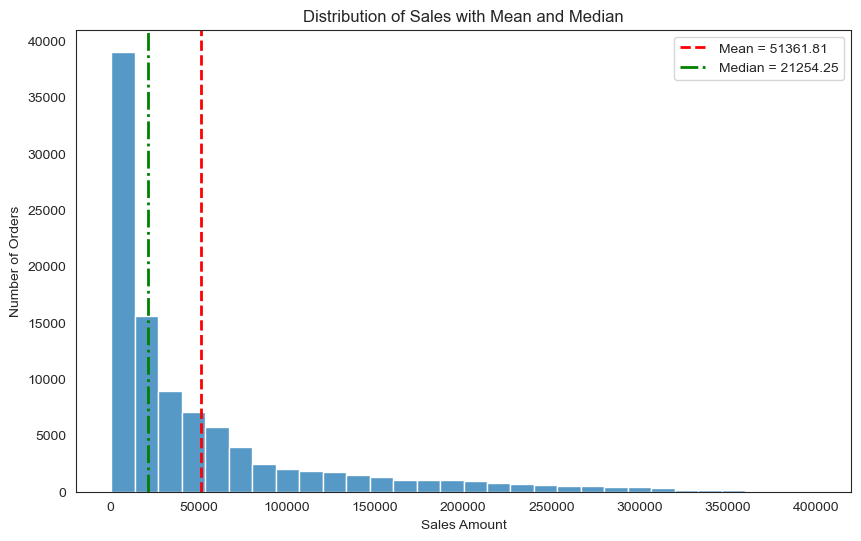

In [193]:
mean = df["Sales"].mean()
median = df["Sales"].median()

plt.figure(figsize=(10,6))
sns.set_style("white")

sns.histplot(data=df, x="Sales", bins=30)

plt.axvline(mean,
            color="red",
            linestyle="--",
            linewidth=2,
            label=f"Mean = {mean:.2f}")
plt.axvline(median,
            color="green",
            linestyle="-.",
            linewidth=2,
            label=f"Median = {median:.2f}")
plt.title("Distribution of Sales with Mean and Median")
plt.xlabel("Sales Amount")
plt.ylabel("Number of Orders")

plt.legend()
plt.show()

# Mean and median are marked
# used hist graph to detect the 

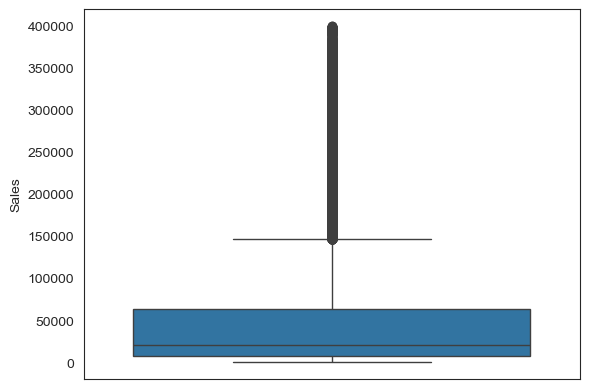

In [194]:
sns.boxplot(y = df["Sales"],data = df)# box plot for outlier detection
plt.show()

### Profit

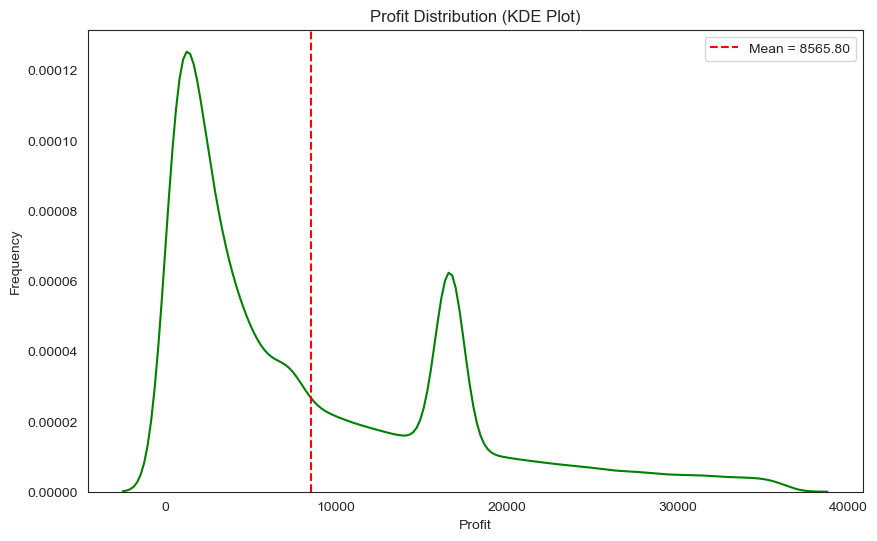

In [195]:
mean=df["Profit"].mean()
plt.figure(figsize=(10,6))
sns.kdeplot(data=df,
           x="Profit",
           color="green",
            )
           
plt.axvline(mean,
           color="red",
           linestyle="--",
            label=f"Mean = {mean:.2f}"
)
plt.ylabel("Frequency")
plt.xlabel("Profit")
plt.title("Profit Distribution (KDE Plot)")
plt.legend()
plt.show()

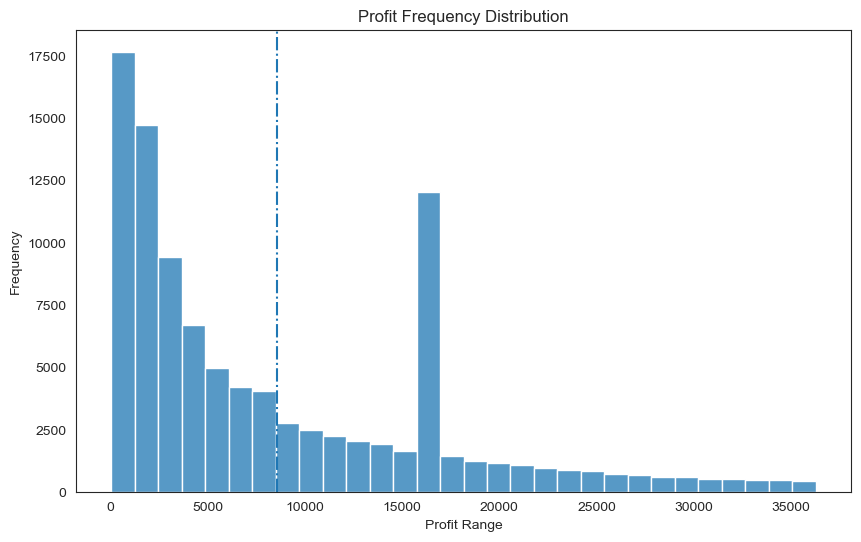

In [196]:
mean=df["Profit"].mean()
median=df["Profit"].median()
plt.figure(figsize=(10,6))
sns.histplot(
    data=df,
    x="Profit",
    bins=30,
    
)
plt.axvline(
    mean,
    linestyle="-."
)
plt.title("Profit Frequency Distribution")
plt.xlabel("Profit Range")
plt.ylabel("Frequency")
plt.show()

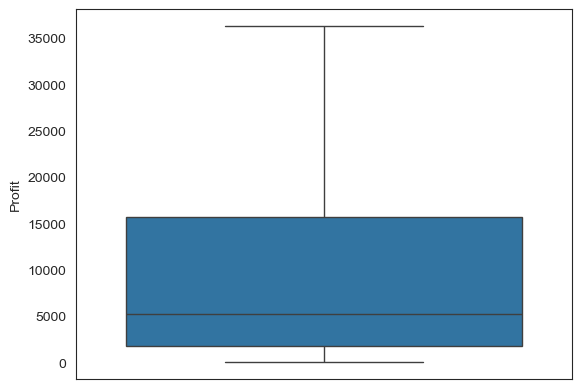

In [197]:
sns.boxplot(y = df["Profit"],data = df)# box plot for outlier detection
plt.show()

### Discount

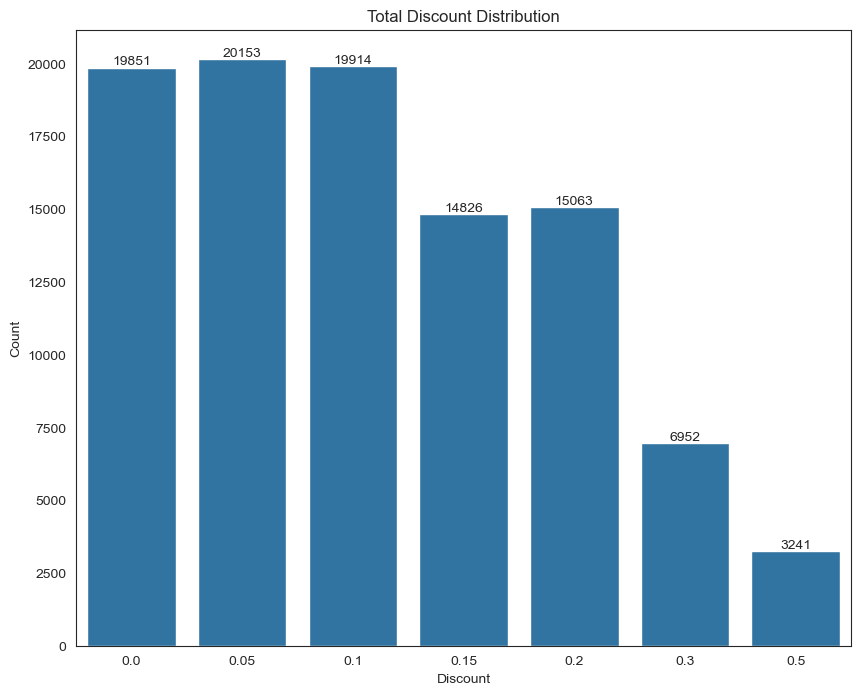

In [198]:


plt.figure(figsize=(10,8))
ax= sns.countplot(data=df,
              x="Discount",
             )
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
plt.title("Total Discount Distribution")
plt.xlabel("Discount")
plt.ylabel("Count")
plt.show()

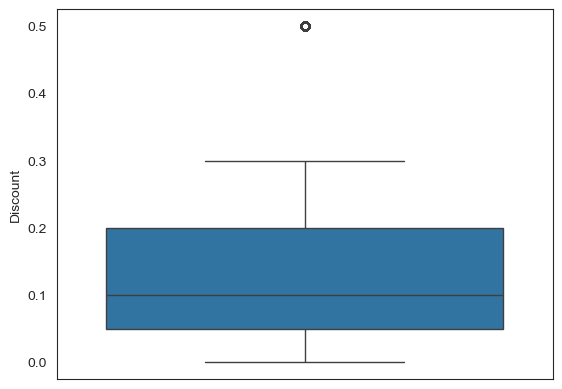

In [199]:
sns.boxplot(data=df,y="Discount")
plt.show()

### Quantity

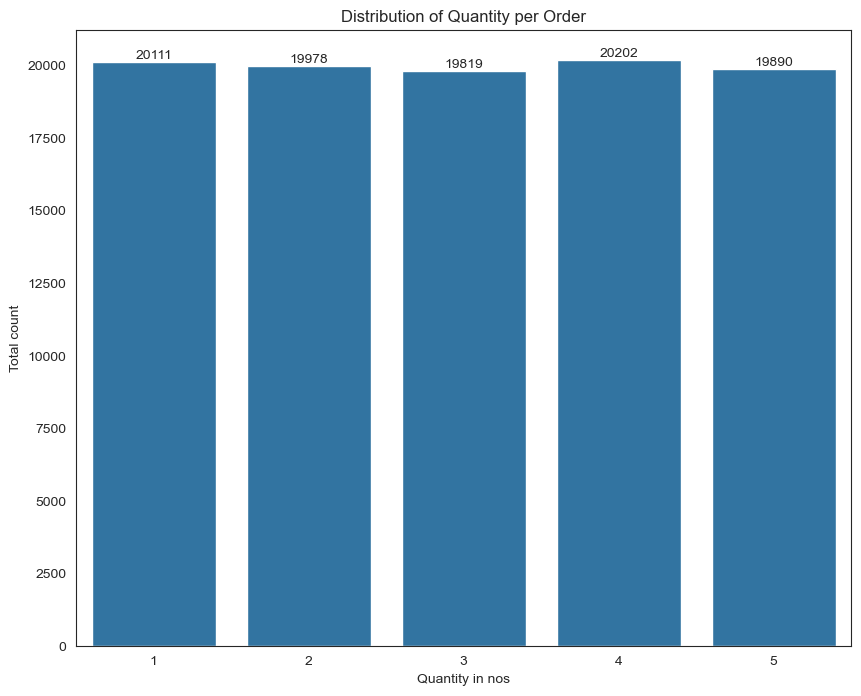

In [200]:
plt.figure(figsize=(10,8))
ax= sns.countplot(data=df,x="Quantity")
for i in ax.containers:
    ax.bar_label(i)
plt.xlabel("Quantity in nos")
plt.ylabel("Total count")
plt.title("Distribution of Quantity per Order")
plt.show()

### Shipping Cost

In [201]:
df["Shipping_Cost"].sort_values().unique().size

450

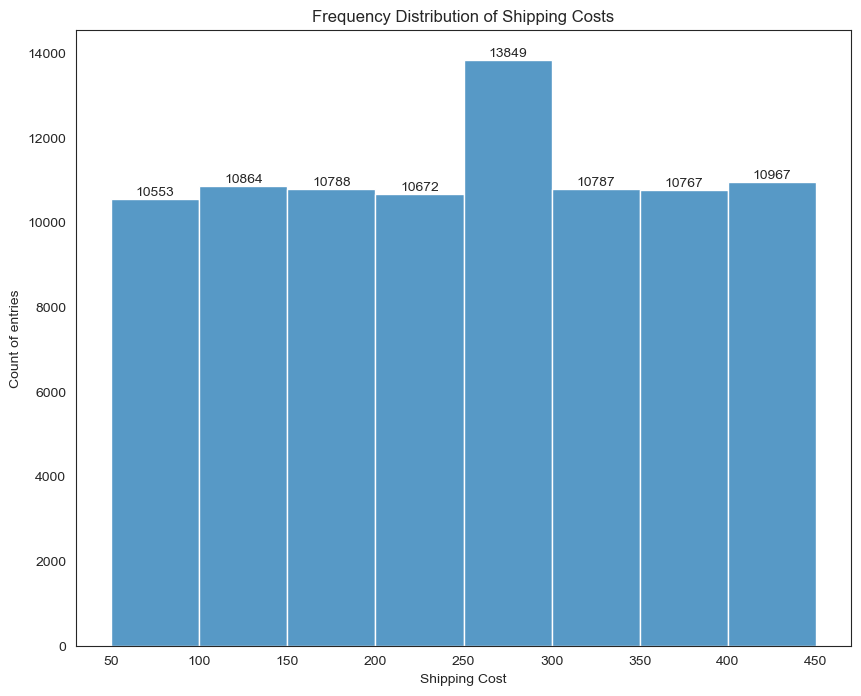

In [202]:
plt.figure(figsize=(10,8))
ab=sns.histplot(data=df,
             x="Shipping_Cost",
            bins=[50,100,150,200,250,300,350,400,450])
for c in ab.containers :
    ab.bar_label(c)
plt.xlabel("Shipping Cost")
plt.ylabel("Count of entries")
plt.title("Frequency Distribution of Shipping Costs")
plt.show()

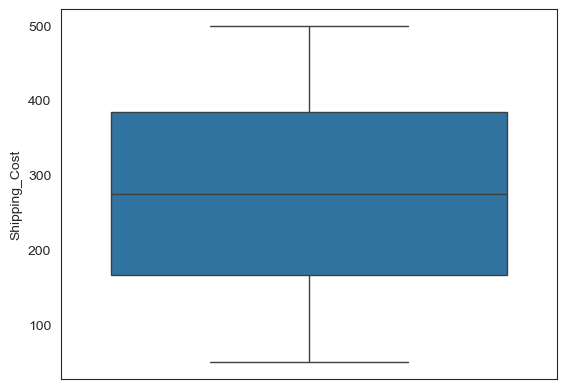

In [203]:
sns.boxplot(y ="Shipping_Cost",data = df) # box plot for outlier detection
plt.show()

## Bivariate Analysis

### Sales vs profit

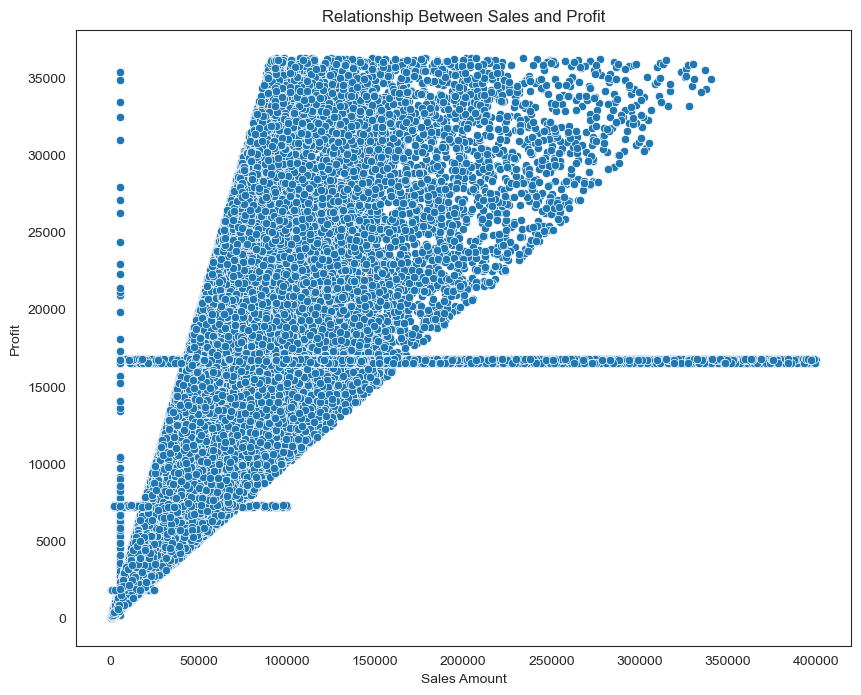

In [204]:
plt.figure(figsize=(10,8))

sns.scatterplot(data=df, x="Sales", y="Profit")

plt.title("Relationship Between Sales and Profit")
plt.xlabel("Sales Amount")
plt.ylabel("Profit")

plt.show()

### Shipping cost vs Profit

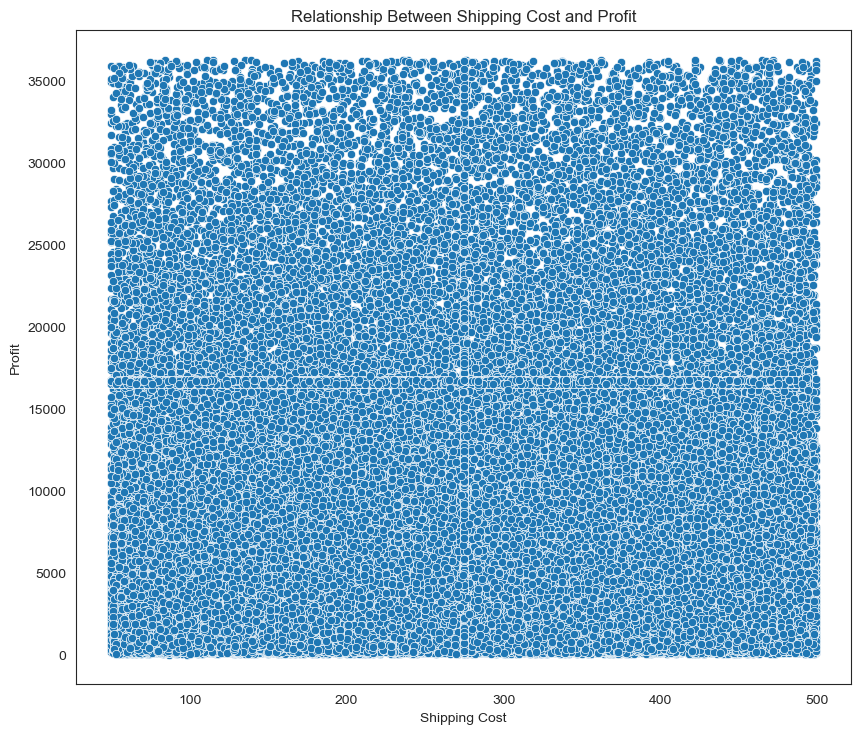

In [205]:
plt.figure(figsize=(10,8.5))

sns.scatterplot(
    data=df,
    x="Shipping_Cost",
    y="Profit"
)

plt.title("Relationship Between Shipping Cost and Profit")
plt.xlabel("Shipping Cost")
plt.ylabel("Profit")


plt.show()

### Product category vs Profit

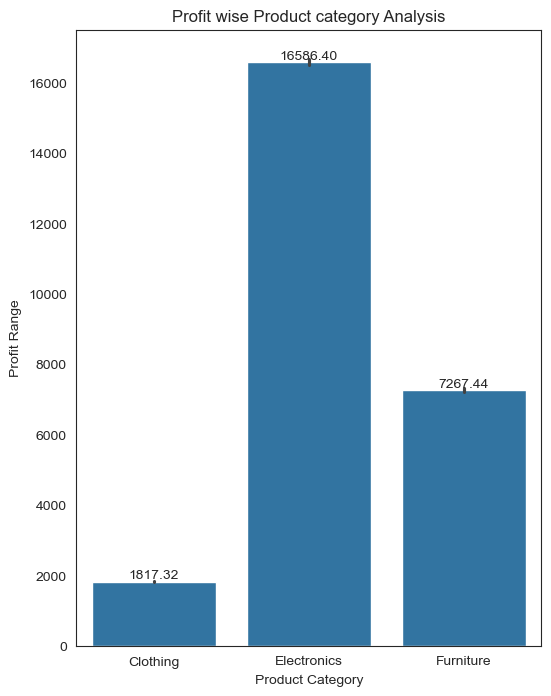

In [206]:
plt.figure(figsize=(6,8))
ax=sns.barplot(data=df,
           x="Product_Category",
           y="Profit")
for c in ax.containers :
    ax.bar_label(c,fmt="%.2f")
plt.xlabel("Product Category")
plt.ylabel("Profit Range")
plt.title("Profit wise Product category Analysis")
plt.show()

### Region vs Profit

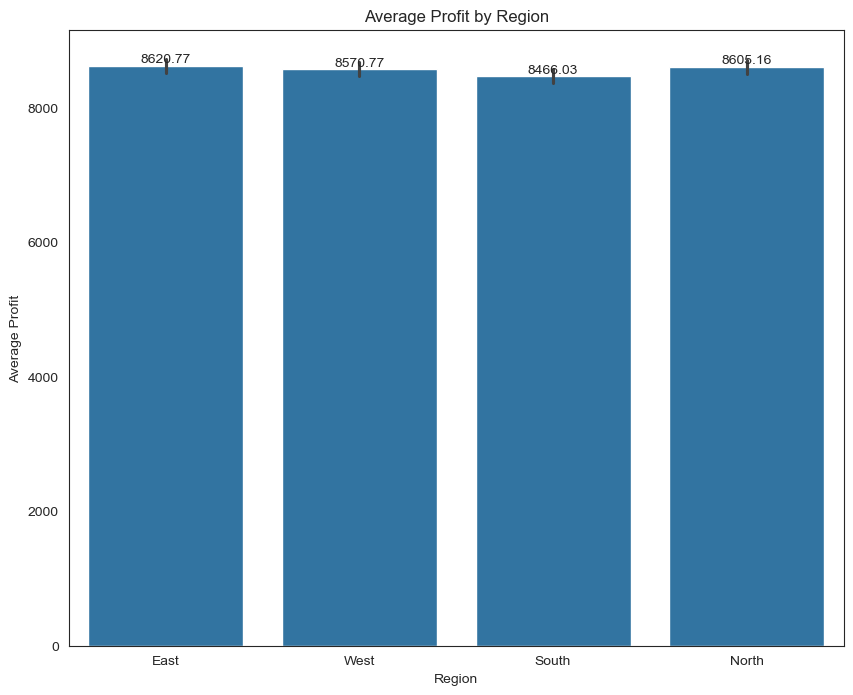

In [207]:
plt.figure(figsize=(10,8))

ax = sns.barplot(
    data=df,
    x="Region",
    y="Profit"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")

plt.xlabel("Region")
plt.ylabel("Average Profit")
plt.title("Average Profit by Region")

plt.show()

### Discount VS Profit

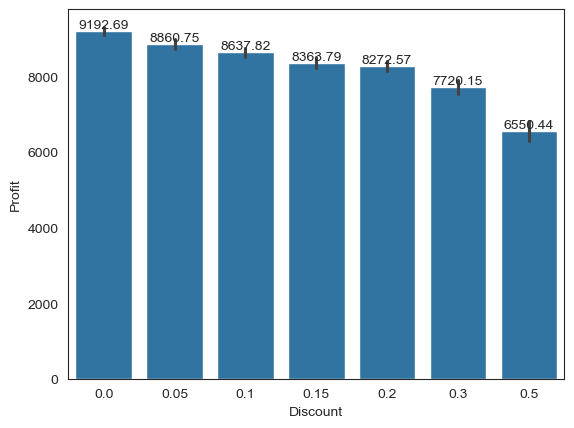

In [208]:

ab=sns.barplot(x = df["Discount"],y = df["Profit"],data = df)
for c in ab.containers :
    ab.bar_label(c)
plt.show() # barplot to find the relation between the discount and profit

### Relation analysis

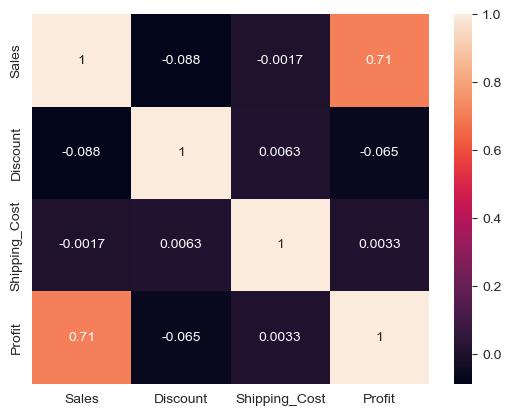

In [209]:
sns.heatmap(df[["Sales","Discount","Shipping_Cost","Profit"]].corr(),annot = True)
plt.show()# ploting heatmap inorder to find the realtion between sales,discount,shipping cost and profit 

## Categoral Analysis

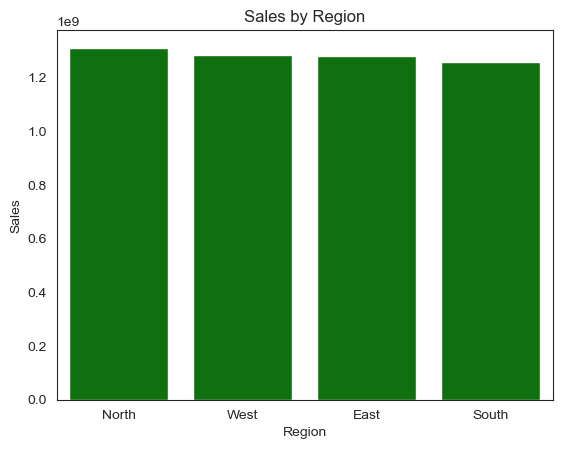

In [210]:
a = df.groupby("Region")["Sales"].sum().sort_values(ascending= False).to_frame().reset_index() # grouping sales by region and sorting and converting to datafarame
ab=sns.barplot(x =a["Region"],y = a["Sales"],data = a,color = "green")

plt.title("Sales by Region")
plt.show() # sales by region plot

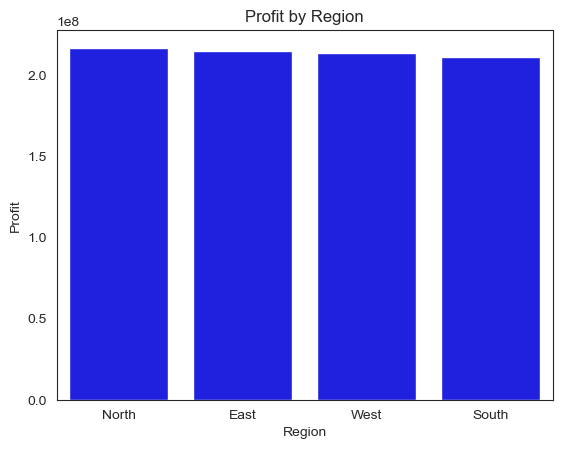

In [211]:
b = df.groupby("Region")["Profit"].sum().sort_values(ascending= False).to_frame().reset_index() # grouping profit by region and sorting and converting to datafarame
sns.barplot(x =b["Region"],y = b["Profit"],data = b,color = "blue")
plt.title("Profit by Region")
plt.show()# region wise profit plot

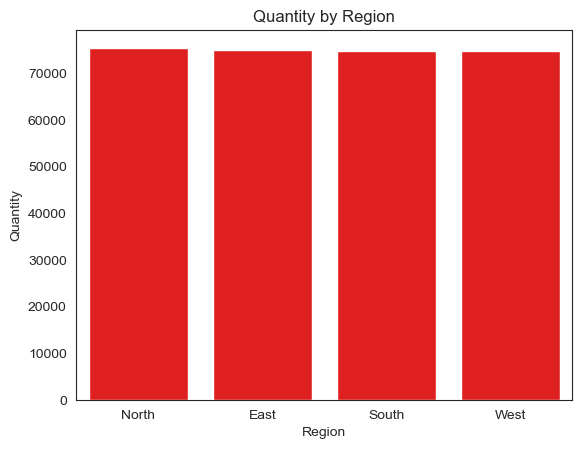

In [212]:
c = df.groupby("Region")["Quantity"].sum().sort_values(ascending= False).to_frame().reset_index() # grouping quantity by region and sorting and converting to datafarame
sns.barplot(x =c["Region"],y = c["Quantity"],data = c,color = "red")
plt.title("Quantity by Region")
plt.show()# region wise quantity sold

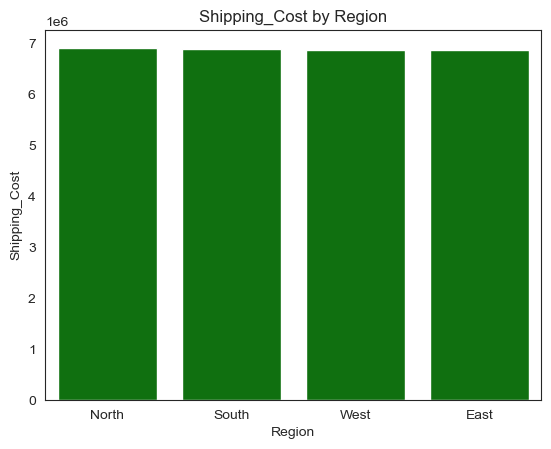

In [213]:
d = df.groupby("Region")["Shipping_Cost"].sum().sort_values(ascending= False).to_frame().reset_index() # grouping shipping cost by region and sorting and converting to datafarame
sns.barplot(x =d["Region"],y = d["Shipping_Cost"],data = d,color = "green")
plt.title("Shipping_Cost by Region")
plt.show()# region wise shipping cost plot

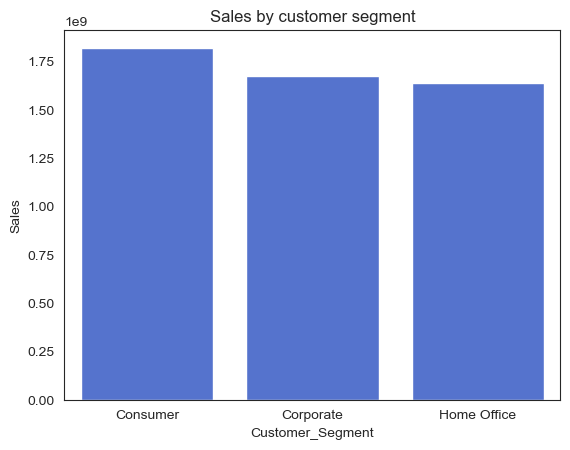

In [214]:
e = df.groupby("Customer_Segment")["Sales"].sum().sort_values(ascending= False).to_frame().reset_index() # grouping sales by customer segment and sorting and converting to datafarame
sns.barplot(x =e["Customer_Segment"],y = e["Sales"],data = e,color = "royalblue")
plt.title("Sales by customer segment")
plt.show()# customer segemnt wise sales

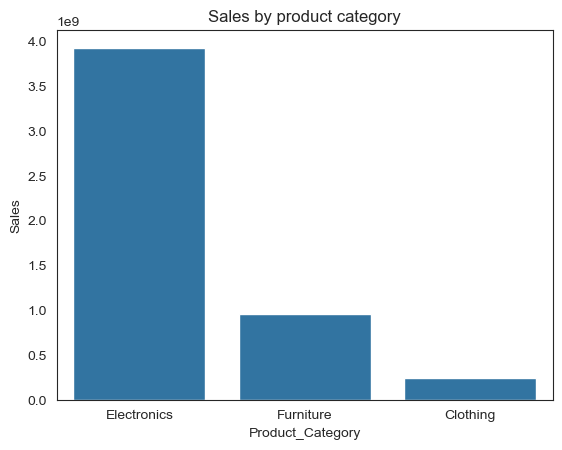

In [215]:
f = df.groupby("Product_Category")["Sales"].sum().sort_values(ascending= False).to_frame().reset_index() # grouping sales by customer segment and sorting and converting to datafarame
sns.barplot(x =f["Product_Category"],y = f["Sales"],data = f)
plt.title("Sales by product category")
plt.show()# sales distribution over product category

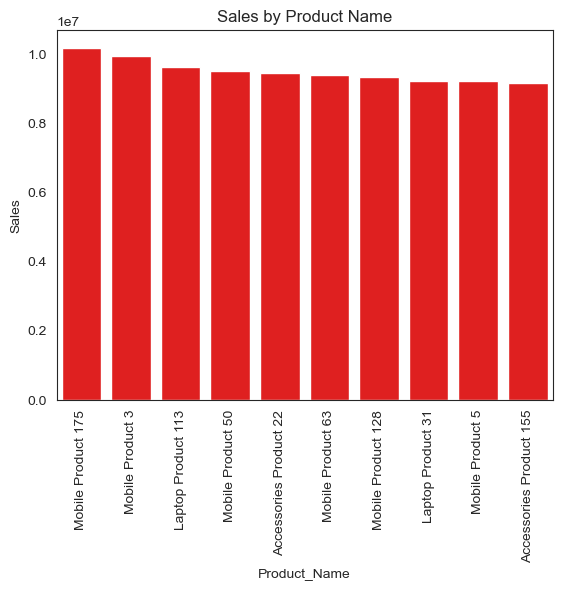

In [216]:
g =df.groupby("Product_Name")["Sales"].sum().sort_values(ascending= False).head(10).to_frame().reset_index() # grouping sales by product name and sorting and converting to datafarame
sns.barplot(x =g["Product_Name"],y = g["Sales"],data = g,color = "red")
plt.title("Sales by Product Name")
plt.xticks(rotation = 90)
plt.show()# sales by product

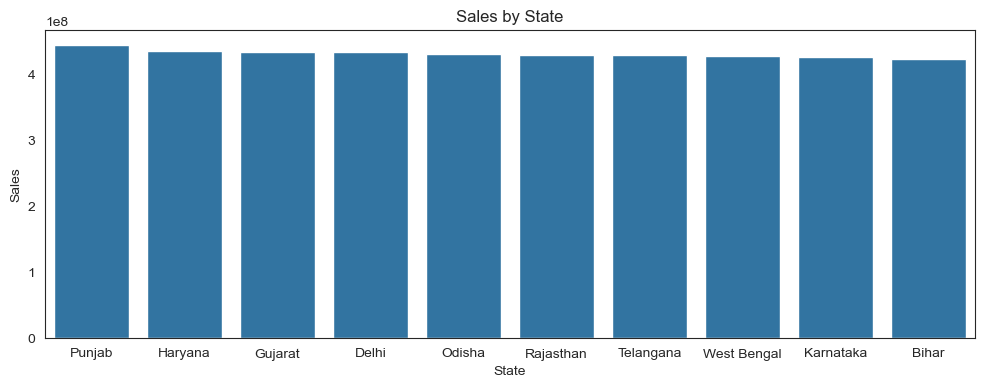

In [217]:
plt.figure(figsize=(12,4))
h =df.groupby("State")["Sales"].sum().sort_values(ascending= False).head(10).to_frame().reset_index() # grouping sales by product name and sorting and converting to datafarame
sns.barplot(x =h["State"],y = h["Sales"],data = h)

plt.title("Sales by State")

plt.show()# sales by state

## Time based analysis

### Monthly Sales

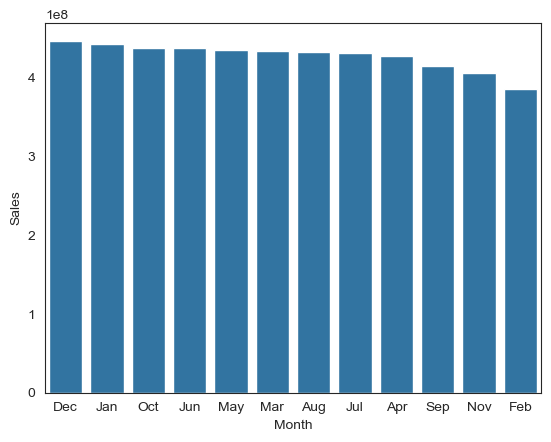

In [218]:
k = df.groupby("Month")["Sales"].sum().sort_values(ascending = False).to_frame().reset_index() # grouping sales by month
sns.barplot(x = k["Month"],y = k["Sales"],data = k)
plt.show()# barplot for analysis of monthly sales

### Quartearly sales

C:\Users\ahlad\AppData\Local\Temp\ipykernel_15920\1646144575.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  l = df.groupby("Quarter")["Sales"].sum().sort_values(ascending = False).to_frame().reset_index()


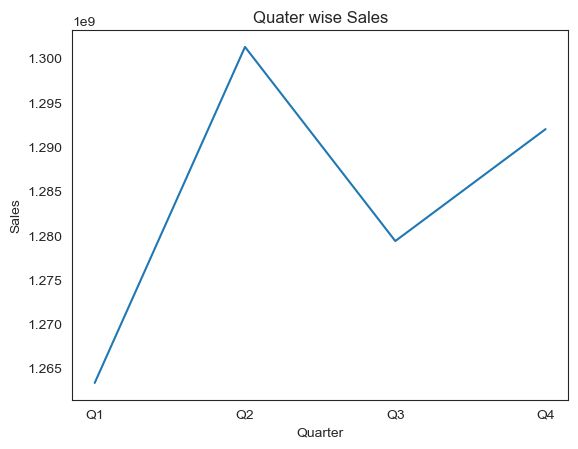

In [219]:
df["Quarter"] = pd.cut(df["Month_num"],bins = [0,3,6,9,12],labels = ["Q1","Q2","Q3","Q4"])
l = df.groupby("Quarter")["Sales"].sum().sort_values(ascending = False).to_frame().reset_index()
sns.lineplot(x = l["Quarter"],y = l["Sales"],data = l)
plt.title("Quater wise Sales")
plt.show()# making bins for 4 quarters, and ploting sales by quarter

### Seasonal Analysis

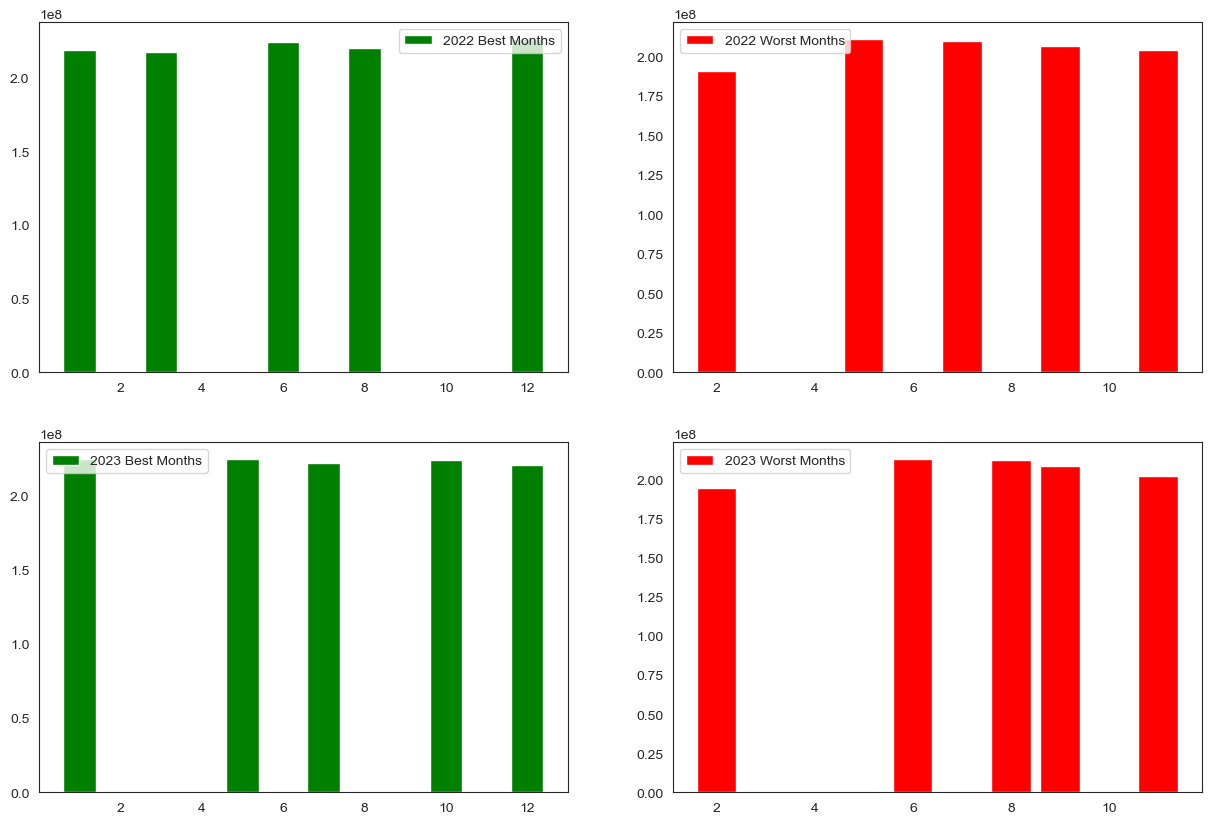

In [220]:
m = df[df["Year"] == 2022]
n = df[df["Year"] == 2023]
A=m.groupby("Month_num")["Sales"].sum().sort_values(ascending = False).head(5).to_frame().reset_index()
B =n.groupby("Month_num")["Sales"].sum().sort_values(ascending = False).head(5).to_frame().reset_index()
C = m.groupby("Month_num")["Sales"].sum().sort_values().head(5).to_frame().reset_index()
D = n.groupby("Month_num")["Sales"].sum().sort_values().head(5).to_frame().reset_index()
plt.figure(figsize = (15,10))
plt.subplot(2,2,1)
plt.bar(A["Month_num"],A["Sales"],color = "green",label= "2022 Best Months")
plt.legend()
plt.subplot(2,2,2)
plt.bar(C["Month_num"],C["Sales"],color = "red",label= "2022 Worst Months")
plt.legend()
plt.subplot(2,2,3)
plt.bar(B["Month_num"],B["Sales"],color = "green",label= "2023 Best Months")
plt.legend()
plt.subplot(2,2,4)
plt.bar(D["Month_num"],D["Sales"],color = "red",label= "2023 Worst Months")
plt.legend()
plt.show() # ploting of four plots to find the seasonality of sales of 2022 and 2023

## Costumer Sales Analysis

### Top 20% costumers contrib

In [221]:
t = df.groupby("Customer_ID")["Sales"].sum().sort_values(ascending = False).to_frame().reset_index()
m = t.loc[:int(len(t)*0.2),"Sales"]
top_20_contri = (m.values.sum()/t.values.sum())
top_20_contri*100 # finding the percentage of sales contribution by top 20% customers

np.float64(29.803031604754366)

### Repeat costumer behaviour

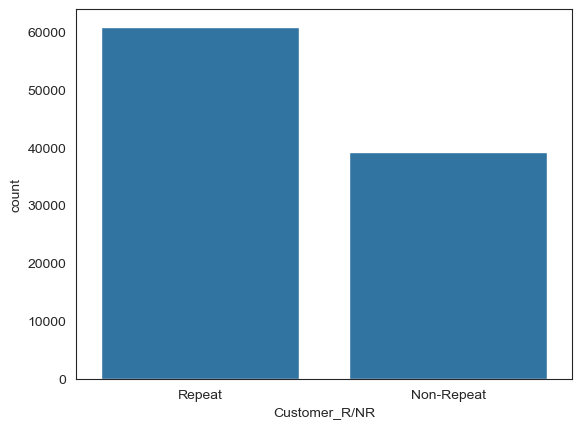

In [222]:
df["Order_count"] = df.groupby("Customer_ID")["Order_ID"].transform("count")
df["Customer_R/NR"] = np.where(df["Order_count"] > 24,"Repeat","Non-Repeat")
p = df["Customer_R/NR"].value_counts().to_frame().reset_index()
sns.barplot(x = p["Customer_R/NR"],y = p["count"],data =  p)
plt.show()# created new column for repeat and non-repeat customers and plotted the count of them 

In [223]:
s =df.groupby("Customer_Segment").agg({"Sales": "sum","Order_ID":"count"}).reset_index()
s["AOV"] = s["Sales"]/s["Order_ID"]
s# finding the average order value by customer segment

,Customer_Segment,Sales,Order_ID,AOV
0,Consumer,1.821400e+09,35483,51331.632175
1,Corporate,1.673537e+09,32136,52076.691032
2,Home Office,1.641245e+09,32381,50685.419961


## Correlation Analysis

### correlation matrix

In [224]:
corr_mat = df[["Sales","Quantity","Discount","Shipping_Cost","Shipping_days","Month_num","Profit"]].corr()
corr_mat# drawing the correlation matrix for easy analysis of the relations between the different columns in datset

,Sales,Quantity,Discount,Shipping_Cost,Shipping_days,Month_num,Profit
Sales,1.000000,0.349134,-0.088260,-0.001686,-0.004417,0.000588,0.708868
Quantity,0.349134,1.000000,-0.001281,-0.006155,0.000753,-0.001910,0.276437
Discount,-0.088260,-0.001281,1.000000,0.006347,-0.001193,0.001801,-0.065031
Shipping_Cost,-0.001686,-0.006155,0.006347,1.000000,-0.004130,-0.000805,0.003308
Shipping_days,-0.004417,0.000753,-0.001193,-0.004130,1.000000,0.000048,-0.004478
Month_num,0.000588,-0.001910,0.001801,-0.000805,0.000048,1.000000,0.003866
Profit,0.708868,0.276437,-0.065031,0.003308,-0.004478,0.003866,1.000000


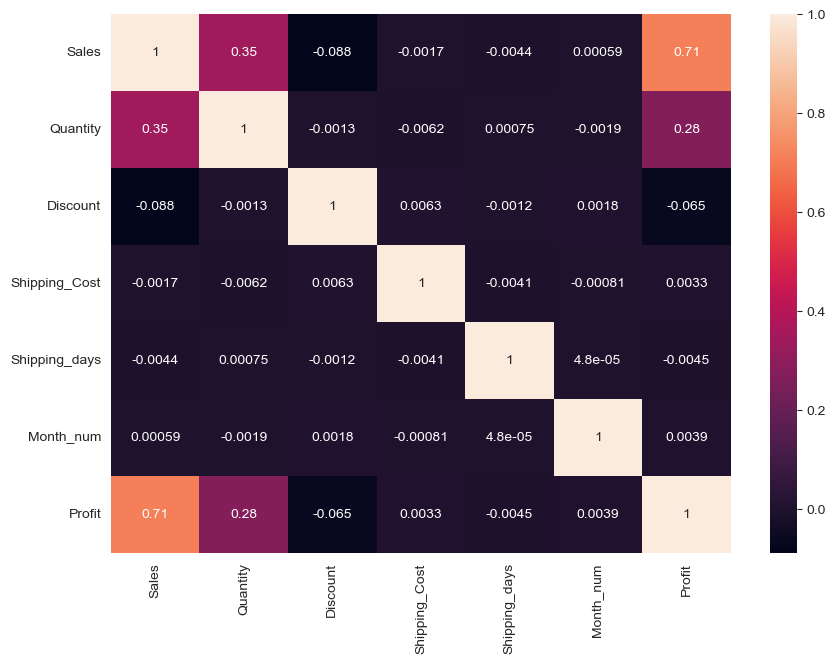

In [225]:
plt.figure(figsize = (10,7))
sns.heatmap(corr_mat,annot = True)
plt.show()#  plotting heatmap for visual analysis

### Strong Relations

<Axes: >

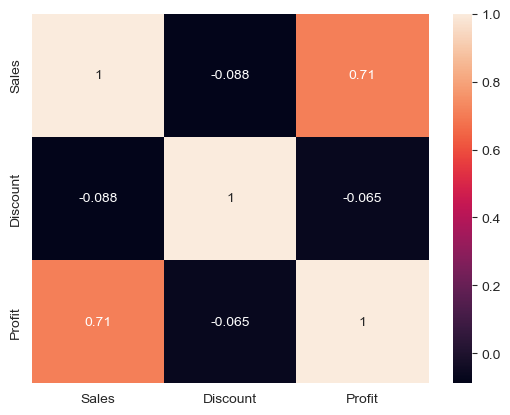

In [226]:
sns.heatmap(df[["Sales","Discount","Profit"]].corr(),annot = True)#  plotting heatmap for visual analysis to find relation between sales,discount and profit

The strong relation apperas at
1. Sales -- Profit and quantity
2. Profit -- Sales

## Phase 3

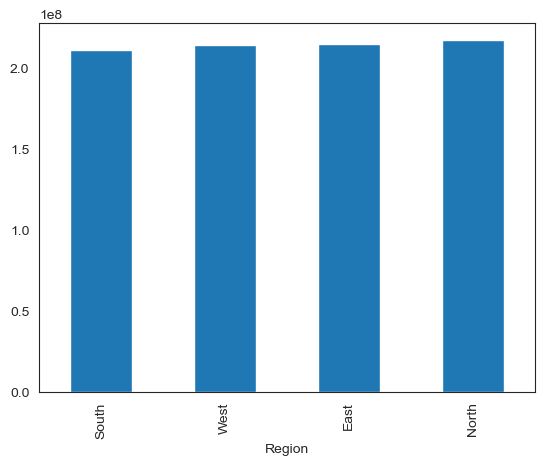

In [227]:
df.groupby("Region")["Profit"].sum().sort_values().plot(kind = "bar")# region wise profit plot 
plt.show()

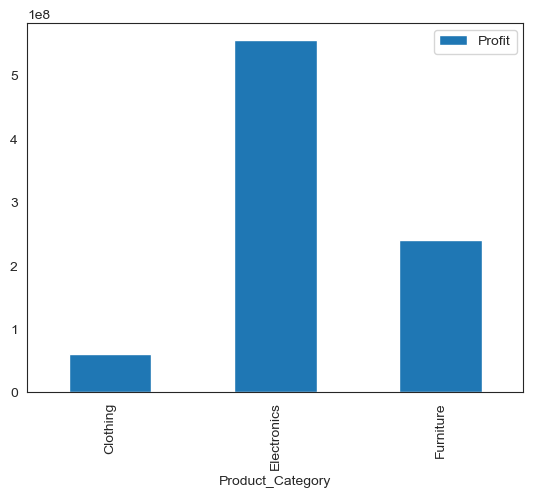

In [228]:
df.groupby("Product_Category").agg({"Profit":"sum"}).plot(kind = "bar")# profit by product category plot 
plt.show()

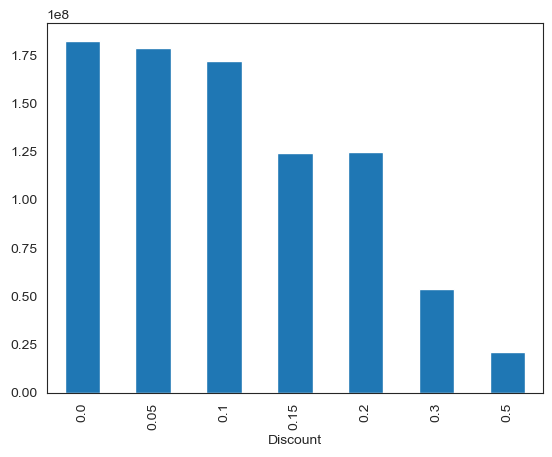

In [229]:
df.groupby("Discount")["Profit"].sum().plot(kind = "bar") # profit based on diff discount values plot
plt.show()

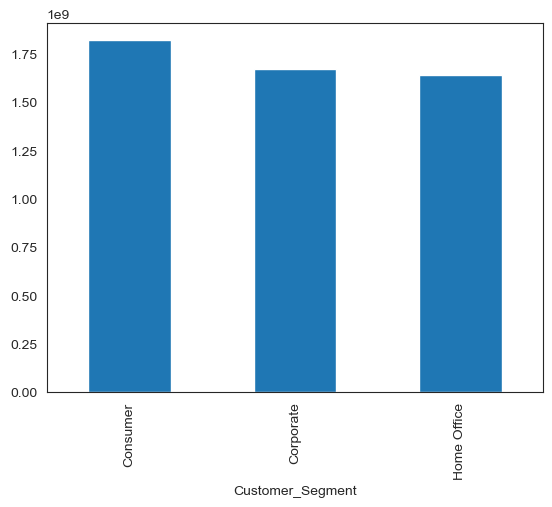

In [230]:
df.groupby("Customer_Segment")["Sales"].sum().plot(kind = "bar")# sales by customer segment plot
plt.show()

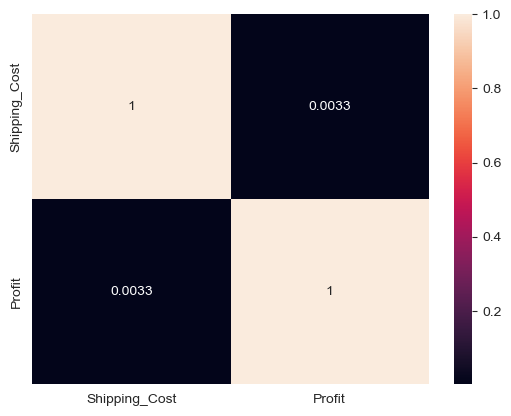

In [231]:
sns.heatmap(df[["Shipping_Cost","Profit"]].corr(),annot = True) # shipping cost no impact on the profits 
plt.show()

1. Develop targeted marketing strategies for high-performing products to boost sales.
2. Optimize discount policies to improve profitability without reducing customer demand.
3. Strengthen business operations in profitable regions while improving weaker markets.
4. Enhance customer retention through loyalty programs and personalized offers.
5. Streamline shipping and logistics to reduce costs and improve operational efficiency.

In [232]:
#### Export 
df.to_csv("e-commerce_cleaned.csv",index = False)